# 8. Predictive Modeling

## 8.1 Loading the Prepared Dataset

The dataset prepared in the previous notebook was loaded for predictive modeling.

It contains:

- 24 selected predictors,
- the binary target variable `high_future_review_activity`,
- listing and host identifiers (`id` and `host_id`),
- predefined training, validation, and test assignments.

The data is not split again. Instead, the existing assignments stored in the `split` column are preserved to ensure consistency with the data preparation stage.

Missing values are intentionally retained and will be handled during preprocessing, with imputation parameters fitted exclusively on the training data.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

RANDOM_STATE = 42
TARGET_COLUMN = "high_future_review_activity"

DATA_PATH = Path(
    "/kaggle/input/datasets/oskarsall/"
    "airbnb-london-prepared-ml-dataset-2025-2026/"
    "airbnb_london_model_input_raw.parquet"
)

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

df_model = pd.read_parquet(DATA_PATH)

META_COLUMNS = ["id", "host_id", "split"]

FEATURE_COLUMNS = [
    column
    for column in df_model.columns
    if column not in META_COLUMNS + [TARGET_COLUMN]
]

print("Dataset path:", DATA_PATH)
print("Dataset shape:", df_model.shape)
print("Number of predictors:", len(FEATURE_COLUMNS))
print("Duplicate listing IDs:", df_model["id"].duplicated().sum())
print(
    "Missing predictor values:",
    df_model[FEATURE_COLUMNS].isna().sum().sum()
)

display(
    df_model["split"]
    .value_counts()
    .rename_axis("split")
    .reset_index(name="count")
)

Dataset path: /kaggle/input/datasets/oskarsall/airbnb-london-prepared-ml-dataset-2025-2026/airbnb_london_model_input_raw.parquet
Dataset shape: (28545, 28)
Number of predictors: 24
Duplicate listing IDs: 0
Missing predictor values: 6434


,split,count
0,train,17044
1,test,5969
2,validation,5532


## 8.2 Restoring the Training, Validation, and Test Sets

The training, validation, and test sets were reconstructed using the `split` column created during data preparation.

No additional random splitting was performed. Each listing retained its original assignment, preserving the host-disjoint data partition established in the previous notebook.

Missing values were left unchanged and will be handled within preprocessing pipelines fitted exclusively on the training data.

In [2]:
df_train_raw = (
    df_model.loc[df_model["split"] == "train"]
    .copy()
    .reset_index(drop=True)
)

df_val_raw = (
    df_model.loc[df_model["split"] == "validation"]
    .copy()
    .reset_index(drop=True)
)

df_test_raw = (
    df_model.loc[df_model["split"] == "test"]
    .copy()
    .reset_index(drop=True)
)

X_train_raw = df_train_raw[FEATURE_COLUMNS].copy()
X_val_raw = df_val_raw[FEATURE_COLUMNS].copy()
X_test_raw = df_test_raw[FEATURE_COLUMNS].copy()

y_train = df_train_raw[TARGET_COLUMN].copy()
y_val = df_val_raw[TARGET_COLUMN].copy()
y_test = df_test_raw[TARGET_COLUMN].copy()

groups_train = df_train_raw["host_id"].copy()

split_check = pd.DataFrame({
    "dataset": ["train", "validation", "test"],
    "n_samples": [
        len(X_train_raw),
        len(X_val_raw),
        len(X_test_raw)
    ],
    "n_features": [
        X_train_raw.shape[1],
        X_val_raw.shape[1],
        X_test_raw.shape[1]
    ],
    "missing_values": [
        X_train_raw.isna().sum().sum(),
        X_val_raw.isna().sum().sum(),
        X_test_raw.isna().sum().sum()
    ],
    "positive_class_pct": [
        y_train.mean() * 100,
        y_val.mean() * 100,
        y_test.mean() * 100
    ]
}).round(2)

display(split_check)

,dataset,n_samples,n_features,missing_values,positive_class_pct
0,train,17044,24,3832,39.40
1,validation,5532,24,1328,42.55
2,test,5969,24,1274,39.60


## 8.3 Defining the Structural Feature Set

The main objective of the predictive modeling stage is to assess whether future review activity can be predicted using listing characteristics, host attributes, location, pricing, and availability.

Two variables describing historical review activity were excluded from the main feature set:

- `number_of_reviews_ltm`,
- `number_of_reviews_l30d`.

Including these variables could cause the models to rely heavily on past review activity, effectively predicting the continuation of previous popularity rather than identifying structural characteristics associated with future review activity.

Their exclusion was not motivated by data leakage, as both variables were available in September 2025, before the prediction period. Instead, it was a deliberate methodological decision aligned with the research objective.

The resulting structural feature set contains **22 predictors**.

In [3]:
HISTORY_FEATURES_TO_REMOVE = [
    "number_of_reviews_ltm",
    "number_of_reviews_l30d"
]

CATEGORICAL_FEATURES = [
    "host_response_time",
    "neighbourhood_cleansed",
    "property_type"
]

BINARY_FEATURES = [
    "host_has_profile_pic",
    "host_identity_verified",
    "instant_bookable"
]

NUMERIC_FEATURES = [
    "host_response_rate",
    "host_acceptance_rate",
    "calculated_host_listings_count_entire_homes",
    "host_tenure_years",
    "distance_to_center_km",
    "accommodates",
    "bathrooms",
    "bedrooms",
    "price",
    "price_per_person",
    "minimum_nights",
    "availability_30",
    "availability_365",
    "name_length",
    "description_length",
    "amenities_count"
]

FEATURE_COLUMNS = (
    CATEGORICAL_FEATURES
    + BINARY_FEATURES
    + NUMERIC_FEATURES
)

assert len(FEATURE_COLUMNS) == 22
assert not set(HISTORY_FEATURES_TO_REMOVE) & set(FEATURE_COLUMNS)

X_train_raw = df_train_raw[FEATURE_COLUMNS].copy()
X_val_raw = df_val_raw[FEATURE_COLUMNS].copy()
X_test_raw = df_test_raw[FEATURE_COLUMNS].copy()

structural_feature_summary = pd.Series({
    "categorical_features": len(CATEGORICAL_FEATURES),
    "binary_features": len(BINARY_FEATURES),
    "numerical_features": len(NUMERIC_FEATURES),
    "total_predictors": len(FEATURE_COLUMNS),
    "missing_train": X_train_raw.isna().sum().sum(),
    "missing_validation": X_val_raw.isna().sum().sum(),
    "missing_test": X_test_raw.isna().sum().sum()
})

display(structural_feature_summary)

display(
    pd.Series(
        FEATURE_COLUMNS,
        name="structural_feature"
    )
)

categorical_features       3
binary_features            3
numerical_features        16
total_predictors          22
missing_train           3832
missing_validation      1328
missing_test            1274
dtype: int64

0                              host_response_time
1                          neighbourhood_cleansed
2                                   property_type
3                            host_has_profile_pic
4                          host_identity_verified
5                                instant_bookable
6                              host_response_rate
7                            host_acceptance_rate
8     calculated_host_listings_count_entire_homes
9                               host_tenure_years
10                          distance_to_center_km
11                                   accommodates
12                                      bathrooms
13                                       bedrooms
14                                          price
15                               price_per_person
16                                 minimum_nights
17                                availability_30
18                               availability_365
19                                    name_length


## 8.4 Dummy Baseline Classifier

Before training the main machine learning models, a simple baseline classifier was established to provide a reference point for performance evaluation.

The classifier always predicts the majority class observed in the training set, without using any listing features.

This baseline represents a minimum performance benchmark against which more advanced models can be compared.

The classifier was fitted using the training set and evaluated on the validation set. The test set was kept untouched for the final model evaluation.

In [4]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

dummy_model = DummyClassifier(strategy="prior")

dummy_model.fit(
    np.zeros((len(y_train), 1)),
    y_train
)

dummy_val_proba = dummy_model.predict_proba(
    np.zeros((len(y_val), 1))
)[:, 1]

dummy_val_pred = dummy_model.predict(
    np.zeros((len(y_val), 1))
)

dummy_results = pd.Series({
    "ROC AUC": roc_auc_score(y_val, dummy_val_proba),
    "PR AUC": average_precision_score(y_val, dummy_val_proba),
    "Accuracy": accuracy_score(y_val, dummy_val_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_val, dummy_val_pred),
    "Precision": precision_score(y_val, dummy_val_pred, zero_division=0),
    "Recall": recall_score(y_val, dummy_val_pred, zero_division=0),
    "F1": f1_score(y_val, dummy_val_pred, zero_division=0)
})

display(dummy_results.round(4))

ROC AUC              0.5000
PR AUC               0.4255
Accuracy             0.5745
Balanced Accuracy    0.5000
Precision            0.0000
Recall               0.0000
F1                   0.0000
dtype: float64

## 8.5 Common Model Evaluation Function

To ensure consistent and comparable evaluation across all classifiers, a common evaluation function was defined to calculate performance metrics using predicted probabilities for the positive class.

The primary evaluation metrics were **ROC AUC** and **PR AUC (Average Precision)**.

Additional metrics included accuracy, balanced accuracy, precision, recall, and F1-score, calculated using the default classification threshold of 0.5.

At this stage, the threshold of 0.5 serves as a reference point. Threshold optimization will be considered only after the initial model comparison and hyperparameter tuning.

In [5]:
def evaluate_classifier(y_true, y_proba, threshold=0.5):
    y_pred = (y_proba >= threshold).astype("int8")

    return pd.Series({
        "ROC AUC": roc_auc_score(y_true, y_proba),
        "PR AUC": average_precision_score(y_true, y_proba),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced accuracy": balanced_accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0)
    })


dummy_results = evaluate_classifier(
    y_true=y_val,
    y_proba=dummy_val_proba,
    threshold=0.5
)

display(dummy_results.round(4))

ROC AUC              0.5000
PR AUC               0.4255
Accuracy             0.5745
Balanced accuracy    0.5000
Precision            0.0000
Recall               0.0000
F1                   0.0000
dtype: float64

## 8.6 Logistic Regression – Structural Feature Model

### 8.6.1 Preprocessing Pipeline

A preprocessing pipeline was constructed for logistic regression using the 22 structural predictors.

The following transformations were applied:

- **Numerical features:** Missing values were imputed using the median, followed by standardization.
- **Binary features:** Missing values were replaced with the most frequent value.
- **Categorical features:** Missing values were treated as a separate category, followed by one-hot encoding. Infrequent categories were grouped together.

All preprocessing parameters were learned exclusively from the training data to prevent data leakage into the validation and test sets.

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="constant", fill_value="missing")
    ),
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="infrequent_if_exist",
            min_frequency=100
        )
    )
])

binary_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    )
])

numeric_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    )
])

logistic_preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", categorical_pipeline, CATEGORICAL_FEATURES),
        ("binary", binary_pipeline, BINARY_FEATURES),
        ("numeric", numeric_pipeline, NUMERIC_FEATURES)
    ],
    remainder="drop"
)

print("Logistic regression preprocessing pipeline initialized.")

Logistic regression preprocessing pipeline initialized.


### 8.6.2 Fitting the Baseline Logistic Regression Model

The baseline logistic regression model was fitted on the training set using the previously defined preprocessing pipeline.

The model uses only the 22 structural predictors, excluding historical review activity.

A default classification threshold of 0.5 was adopted for the initial evaluation.

At this stage, no hyperparameter tuning or cross-validation was performed. The test set remained untouched.

In [7]:
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("preprocessor", logistic_preprocessor),
    (
        "classifier",
        LogisticRegression(
            max_iter=2000,
            solver="liblinear",
            random_state=RANDOM_STATE
        )
    )
])

logistic_model.fit(X_train_raw, y_train)

logistic_val_proba = logistic_model.predict_proba(
    X_val_raw
)[:, 1]

logistic_val_results = evaluate_classifier(
    y_true=y_val,
    y_proba=logistic_val_proba,
    threshold=0.5
)

display(logistic_val_results.round(4))

ROC AUC              0.8061
PR AUC               0.7153
Accuracy             0.7249
Balanced accuracy    0.7207
Precision            0.6713
Recall               0.6924
F1                   0.6817
dtype: float64

### 8.6.3 Baseline Logistic Regression Results

The logistic regression model demonstrated a meaningful ability to distinguish between listings with high and low future review activity, substantially outperforming the dummy baseline.

The relatively balanced precision and recall indicate that, at the default threshold of 0.5, the model maintains a reasonable trade-off between identifying highly active listings and limiting false positive predictions.

These validation results establish logistic regression as a useful benchmark for evaluating more advanced machine learning models.

In [8]:
model_results = pd.DataFrame({
    "Dummy": dummy_results,
    "Logistic Regression": logistic_val_results
}).T

model_results.index.name = "Model"

display(
    model_results
    .sort_values("ROC AUC", ascending=False)
    .round(4)
)

,ROC AUC,PR AUC,Accuracy,Balanced accuracy,Precision,Recall,F1
Model,,,,,,,
Logistic Regression,0.8061,0.7153,0.7249,0.7207,0.6713,0.6924,0.6817
Dummy,0.5000,0.4255,0.5745,0.5000,0.0000,0.0000,0.0000


## 8.7 Random Forest – Structural Feature Model

### 8.7.1 Fitting the Baseline Model

Random Forest was selected as the second classification algorithm. It combines multiple decision trees and aggregates their predictions to improve predictive performance.

The preprocessing pipeline included:

- **Numerical features:** Missing values were imputed using the median.
- **Binary features:** Missing values were replaced with the most frequent value.
- **Categorical features:** Missing values were treated as a separate category and encoded using one-hot encoding.

Numerical features were not standardized, as tree-based models do not require feature scaling.

The baseline model was fitted on the training set and evaluated on the validation set using a classification threshold of 0.5. Hyperparameter tuning was not performed at this stage.

In [9]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier

rf_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

rf_preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", clone(categorical_pipeline), CATEGORICAL_FEATURES),
        ("binary", clone(binary_pipeline), BINARY_FEATURES),
        ("numeric", rf_numeric_pipeline, NUMERIC_FEATURES)
    ],
    remainder="drop"
)

rf_model = Pipeline([
    ("preprocessor", rf_preprocessor),
    (
        "classifier",
        RandomForestClassifier(
            n_estimators=500,
            max_features="sqrt",
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
    )
])

rf_model.fit(X_train_raw, y_train)

rf_val_proba = rf_model.predict_proba(X_val_raw)[:, 1]

rf_val_results = evaluate_classifier(
    y_true=y_val,
    y_proba=rf_val_proba,
    threshold=0.5
)

display(rf_val_results.round(4))

ROC AUC              0.8400
PR AUC               0.7576
Accuracy             0.7666
Balanced accuracy    0.7611
Precision            0.7267
Recall               0.7239
F1                   0.7253
dtype: float64

### 8.7.2 Baseline Random Forest Results

Random Forest outperformed the baseline logistic regression model across all evaluation metrics, suggesting that a tree-based approach can better capture relationships within the structural features.

The nearly identical precision and recall values indicate a balanced trade-off between detecting listings with high future review activity and limiting false positive predictions.

These results establish Random Forest as a stronger benchmark for subsequent model comparisons.

In [10]:
model_results.loc["Random Forest"] = rf_val_results

display(
    model_results
    .sort_values("ROC AUC", ascending=False)
    .round(4)
)

,ROC AUC,PR AUC,Accuracy,Balanced accuracy,Precision,Recall,F1
Model,,,,,,,
Random Forest,0.8400,0.7576,0.7666,0.7611,0.7267,0.7239,0.7253
Logistic Regression,0.8061,0.7153,0.7249,0.7207,0.6713,0.6924,0.6817
Dummy,0.5000,0.4255,0.5745,0.5000,0.0000,0.0000,0.0000


## 8.8 XGBoost – Structural Feature Model

### 8.8.1 Fitting the Baseline Model

XGBoost was evaluated as a gradient boosting algorithm capable of capturing nonlinear relationships and interactions between predictors.

The model used the same 22 structural features and preprocessing pipeline as Random Forest.

It was trained on the training set using predefined hyperparameters and evaluated on the validation set with a classification threshold of 0.5.

No hyperparameter tuning was performed at this stage, and the test set remained untouched.

In [11]:
from xgboost import XGBClassifier

xgb_model = Pipeline([
    ("preprocessor", clone(rf_preprocessor)),
    (
        "classifier",
        XGBClassifier(
            objective="binary:logistic",
            n_estimators=400,
            learning_rate=0.05,
            max_depth=6,
            subsample=0.8,
            colsample_bytree=0.8,
            tree_method="hist",
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
    )
])

xgb_model.fit(X_train_raw, y_train)

xgb_val_proba = xgb_model.predict_proba(X_val_raw)[:, 1]

xgb_val_results = evaluate_classifier(
    y_true=y_val,
    y_proba=xgb_val_proba,
    threshold=0.5
)

display(xgb_val_results.round(4))

ROC AUC              0.8430
PR AUC               0.7541
Accuracy             0.7684
Balanced accuracy    0.7653
Precision            0.7207
Recall               0.7443
F1                   0.7323
dtype: float64

### 8.8.2 Baseline XGBoost Results

XGBoost demonstrated strong predictive performance, achieving results comparable to Random Forest and outperforming logistic regression.

Compared with Random Forest, XGBoost achieved slightly higher ROC AUC and F1-score, but marginally lower Average Precision. This indicates that neither ensemble method consistently outperformed the other across all evaluation metrics.

Both tree-based models provide promising candidates for further optimization.

In [12]:
model_results.loc["XGBoost"] = xgb_val_results

display(
    model_results
    .sort_values("ROC AUC", ascending=False)
    .round(4)
)

,ROC AUC,PR AUC,Accuracy,Balanced accuracy,Precision,Recall,F1
Model,,,,,,,
XGBoost,0.8430,0.7541,0.7684,0.7653,0.7207,0.7443,0.7323
Random Forest,0.8400,0.7576,0.7666,0.7611,0.7267,0.7239,0.7253
Logistic Regression,0.8061,0.7153,0.7249,0.7207,0.6713,0.6924,0.6817
Dummy,0.5000,0.4255,0.5745,0.5000,0.0000,0.0000,0.0000


## 8.9 CatBoost – Structural Feature Model

### 8.9.1 Fitting the Baseline Model

CatBoost was introduced as another gradient boosting algorithm, designed to handle categorical features directly.

Unlike the previous tree-based models, categorical variables were used without one-hot encoding. Missing categorical values were assigned a separate `missing` category, while numerical missing values were handled natively by CatBoost.



In [13]:
from catboost import CatBoostClassifier

X_train_cat = X_train_raw.copy()
X_val_cat = X_val_raw.copy()

for column in CATEGORICAL_FEATURES:
    X_train_cat[column] = (
        X_train_cat[column].fillna("missing").astype(str)
    )
    X_val_cat[column] = (
        X_val_cat[column].fillna("missing").astype(str)
    )

catboost_model = CatBoostClassifier(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=RANDOM_STATE,
    verbose=0
)

catboost_model.fit(
    X_train_cat,
    y_train,
    cat_features=CATEGORICAL_FEATURES
)

catboost_val_proba = catboost_model.predict_proba(
    X_val_cat
)[:, 1]

catboost_val_results = evaluate_classifier(
    y_true=y_val,
    y_proba=catboost_val_proba,
    threshold=0.5
)

display(catboost_val_results.round(4))

ROC AUC              0.8435
PR AUC               0.7604
Accuracy             0.7616
Balanced accuracy    0.7583
Precision            0.7127
Recall               0.7366
F1                   0.7245
dtype: float64

### 8.9.2 Baseline CatBoost Results

CatBoost achieved the highest ROC AUC and Average Precision among the baseline models, indicating strong discrimination and positive-class ranking performance.

However, the differences compared with Random Forest and XGBoost were relatively small, and CatBoost did not outperform them across all threshold-dependent metrics.

Overall, the three tree-based models demonstrated comparable predictive performance, supporting their consideration in further model optimization.

In [14]:
model_results.loc["CatBoost"] = catboost_val_results

display(
    model_results
    .sort_values("ROC AUC", ascending=False)
    .round(4)
)

,ROC AUC,PR AUC,Accuracy,Balanced accuracy,Precision,Recall,F1
Model,,,,,,,
CatBoost,0.8435,0.7604,0.7616,0.7583,0.7127,0.7366,0.7245
XGBoost,0.8430,0.7541,0.7684,0.7653,0.7207,0.7443,0.7323
Random Forest,0.8400,0.7576,0.7666,0.7611,0.7267,0.7239,0.7253
Logistic Regression,0.8061,0.7153,0.7249,0.7207,0.6713,0.6924,0.6817
Dummy,0.5000,0.4255,0.5745,0.5000,0.0000,0.0000,0.0000


## 8.10 Baseline Model Comparison

CatBoost achieved the highest ROC AUC and Average Precision, while XGBoost obtained the highest F1-score and Random Forest achieved the highest precision.

All three tree-based models performed similarly and outperformed logistic regression, suggesting that nonlinear relationships and feature interactions are important for predicting future review activity.

However, the differences between the tree-based models were relatively small. Performance on a single validation set is insufficient to reliably identify the best algorithm.

Therefore, the next stage evaluates model stability using cross-validation grouped by `host_id`, ensuring that listings belonging to the same host do not appear in both training and validation folds.

### 8.10.1 ROC Curves of Baseline Models

To complement the metric-based comparison, ROC curves were plotted for the baseline models using the validation set.

The curves provide a visual comparison of the trade-off between the true positive rate and the false positive rate across all possible classification thresholds.

This visualization supports the earlier conclusion that the three tree-based models achieve very similar discrimination performance and all outperform logistic regression.

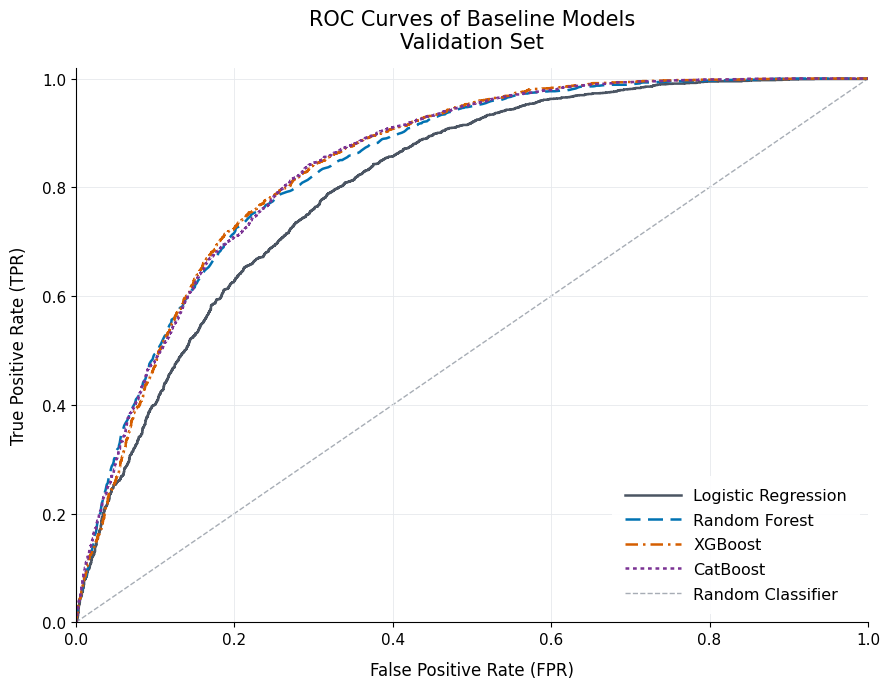

In [15]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, FuncFormatter
from sklearn.metrics import roc_curve

models = [
    ("Logistic Regression", logistic_val_proba, "#4B5563", "-"),
    ("Random Forest", rf_val_proba, "#0072B2", (0, (6, 3))),
    ("XGBoost", xgb_val_proba, "#D55E00", (0, (5, 2, 1, 2))),
    ("CatBoost", catboost_val_proba, "#7B3294", (0, (1.5, 1.5))),
]

fig, ax = plt.subplots(figsize=(9, 7))

for name, probabilities, color, style in models:
    fpr, tpr, _ = roc_curve(y_val, probabilities)

    ax.plot(
        fpr,
        tpr,
        color=color,
        linestyle=style,
        linewidth=1.8,
        label=name,
    )

ax.plot(
    [0, 1],
    [0, 1],
    color="#A7ADB5",
    linestyle="--",
    linewidth=1,
    label="Random Classifier",
    zorder=0,
)

ax.set_title(
    "ROC Curves of Baseline Models\nValidation Set",
    fontsize=15,
    pad=14,
)
ax.set_xlabel(
    "False Positive Rate (FPR)",
    fontsize=12,
    labelpad=10,
)
ax.set_ylabel(
    "True Positive Rate (TPR)",
    fontsize=12,
    labelpad=10,
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

ax.xaxis.set_major_locator(MultipleLocator(0.2))
ax.yaxis.set_major_locator(MultipleLocator(0.2))

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f"{value:.1f}")
)
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f"{value:.1f}")
)

ax.tick_params(labelsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.set_axisbelow(True)
ax.grid(color="#E6E9ED", linewidth=0.6)

ax.legend(
    loc="lower right",
    fontsize=11.5,
    handlelength=3.5,
    frameon=True,
    facecolor="white",
    edgecolor="none",
    framealpha=0.95,
    labelspacing=0.6,
    borderpad=0.8,
)

fig.tight_layout()

fig.savefig(
    "/kaggle/working/baseline_model_roc_curves.png",
    dpi=300,
    bbox_inches="tight",
)
fig.savefig(
    "/kaggle/working/baseline_model_roc_curves.pdf",
    bbox_inches="tight",
)

plt.show()

# 9. Grouped Cross-Validation of Baseline Models

All four baseline models were evaluated using five-fold `StratifiedGroupKFold` cross-validation on the training set.

The same folds were used for every model, with grouping by `host_id` to prevent listings from the same host appearing in both training and validation portions of a fold.

Each model and its preprocessing were fitted independently within each fold. Mean performance and standard deviation were calculated to assess predictive quality and stability.

The external validation and test sets remained untouched.

In [16]:
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.base import clone

group_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_splits = list(
    group_cv.split(X_train_raw, y_train, groups_train)
)

assert all(
    set(groups_train.iloc[tr]).isdisjoint(groups_train.iloc[val])
    for tr, val in cv_splits
)

cv_scoring = {
    "ROC AUC": "roc_auc",
    "PR AUC": "average_precision",
    "Accuracy": "accuracy",
    "Balanced accuracy": "balanced_accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1"
}

cv_models = {
    "Logistic Regression": (
        clone(logistic_model), X_train_raw, {}
    ),
    "Random Forest": (
        clone(rf_model).set_params(classifier__n_jobs=1),
        X_train_raw, {}
    ),
    "XGBoost": (
        clone(xgb_model).set_params(classifier__n_jobs=1),
        X_train_raw, {}
    ),
    "CatBoost": (
        clone(catboost_model).set_params(
            thread_count=1,
            allow_writing_files=False
        ),
        X_train_cat,
        {"cat_features": CATEGORICAL_FEATURES}
    )
}

cv_summaries = {}

for name, (model, X, fit_params) in cv_models.items():
    print(f"Evaluating: {name}")

    scores = cross_validate(
        estimator=model,
        X=X,
        y=y_train,
        cv=cv_splits,
        scoring=cv_scoring,
        n_jobs=2,
        params=fit_params,
        error_score="raise"
    )

    cv_summaries[name] = pd.DataFrame({
        "mean": {
            m: scores[f"test_{m}"].mean() for m in cv_scoring
        },
        "std": {
            m: scores[f"test_{m}"].std(ddof=1) for m in cv_scoring
        }
    })

metrics = ["ROC AUC", "PR AUC", "Balanced accuracy", "F1"]

cv_comparison = pd.DataFrame({
    name: {
        metric: f"{summary.loc[metric, 'mean']:.4f} ± "
                f"{summary.loc[metric, 'std']:.4f}"
        for metric in metrics
    }
    for name, summary in cv_summaries.items()
}).T

cv_comparison.index.name = "Model"

display(cv_comparison)

Evaluating: Logistic Regression
Evaluating: Random Forest
Evaluating: XGBoost
Evaluating: CatBoost


/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


,ROC AUC,PR AUC,Balanced accuracy,F1
Model,,,,
Logistic Regression,0.8036 ± 0.0145,0.6946 ± 0.0025,0.7197 ± 0.0107,0.6641 ± 0.0116
Random Forest,0.8426 ± 0.0185,0.7432 ± 0.0113,0.7541 ± 0.0103,0.7035 ± 0.0125
XGBoost,0.8423 ± 0.0158,0.7406 ± 0.0101,0.7573 ± 0.0107,0.7092 ± 0.0088
CatBoost,0.8455 ± 0.0185,0.7457 ± 0.0170,0.7616 ± 0.0128,0.7145 ± 0.0080


### Cross-Validation Results

The three tree-based models achieved similar cross-validation performance, with CatBoost obtaining the highest mean scores.

Standard deviations indicate some variation across folds, but no substantial differences in stability were observed among the tree-based models. Logistic regression consistently performed worse.

Given the small performance differences, cross-validation alone does not provide a clear basis for selecting the final model.


# 10. Model Selection and Optimization

Following the baseline comparison and grouped cross-validation, XGBoost was selected for further hyperparameter optimization.

Although the tree-based models achieved similar performance, XGBoost was chosen as a competitive candidate for additional optimization. The objective was to determine whether tuning could improve predictive performance beyond the baseline configuration.

## 10.1 XGBoost Hyperparameter Tuning

A randomized search was conducted over 20 hyperparameter configurations using the previously defined five-fold `StratifiedGroupKFold` cross-validation.

Mean ROC AUC was used as the primary selection criterion, while Average Precision was monitored as a secondary metric.

All tuning was performed exclusively on the training set, preserving the external validation and test sets for subsequent evaluation.


In [17]:
from sklearn.model_selection import RandomizedSearchCV

xgb_param_distributions = {
    "classifier__n_estimators": [300, 500, 700, 900],
    "classifier__learning_rate": [0.02, 0.03, 0.05, 0.08, 0.10],
    "classifier__max_depth": [3, 4, 5, 6, 8],
    "classifier__min_child_weight": [1, 3, 5, 8],
    "classifier__subsample": [0.7, 0.8, 0.9, 1.0],
    "classifier__colsample_bytree": [0.6, 0.8, 1.0],
    "classifier__gamma": [0, 0.1, 0.3, 0.5],
    "classifier__reg_alpha": [0, 0.01, 0.1, 0.5, 1.0],
    "classifier__reg_lambda": [1, 2, 5, 10]
}

xgb_search = RandomizedSearchCV(
    estimator=clone(xgb_model).set_params(classifier__n_jobs=1),
    param_distributions=xgb_param_distributions,
    n_iter=20,
    scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision"},
    refit="roc_auc",
    cv=cv_splits,
    n_jobs=2,
    random_state=RANDOM_STATE,
    error_score="raise",
    return_train_score=False
)

xgb_search.fit(X_train_raw, y_train)

xgb_best_params = xgb_search.best_params_
xgb_best_cv_score = xgb_search.best_score_
xgb_search_results = pd.DataFrame(xgb_search.cv_results_)

print("Best grouped CV ROC AUC:", round(xgb_best_cv_score, 4))
display(pd.Series(xgb_best_params, name="value").rename_axis("parameter").to_frame())

display(
    xgb_search_results[
        ["rank_test_roc_auc", "mean_test_roc_auc", "std_test_roc_auc",
         "mean_test_pr_auc", "std_test_pr_auc", "params"]
    ].sort_values("rank_test_roc_auc").head(10).round(4)
)

Best grouped CV ROC AUC: 0.8469


,value
parameter,
classifier__subsample,0.90
classifier__reg_lambda,5.00
classifier__reg_alpha,0.50
classifier__n_estimators,900.00
classifier__min_child_weight,3.00
classifier__max_depth,5.00
classifier__learning_rate,0.02
classifier__gamma,0.00
classifier__colsample_bytree,1.00


,rank_test_roc_auc,mean_test_roc_auc,std_test_roc_auc,mean_test_pr_auc,std_test_pr_auc,params
4,1,0.8469,0.0146,0.7505,0.0105,"{'classifier__subsample': 0.9, 'classifier__re..."
11,2,0.8460,0.0133,0.7493,0.0068,"{'classifier__subsample': 1.0, 'classifier__re..."
16,3,0.8458,0.0150,0.7478,0.0094,"{'classifier__subsample': 0.8, 'classifier__re..."
2,4,0.8457,0.0137,0.7487,0.0095,"{'classifier__subsample': 0.7, 'classifier__re..."
15,5,0.8453,0.0159,0.7464,0.0133,"{'classifier__subsample': 0.9, 'classifier__re..."
9,6,0.8452,0.0142,0.7487,0.0109,"{'classifier__subsample': 0.8, 'classifier__re..."
6,7,0.8451,0.0151,0.7453,0.0124,"{'classifier__subsample': 0.7, 'classifier__re..."
19,8,0.8451,0.0160,0.7477,0.0116,"{'classifier__subsample': 1.0, 'classifier__re..."
12,9,0.8451,0.0146,0.7474,0.0118,"{'classifier__subsample': 1.0, 'classifier__re..."
18,10,0.8450,0.0169,0.7464,0.0166,"{'classifier__subsample': 0.8, 'classifier__re..."


### 10.1.1 Hyperparameter Tuning Results

The randomized search evaluated 20 XGBoost configurations on the same five host-grouped folds as the baseline models. The best configuration was chosen using mean ROC AUC, with Average Precision reported as an additional metric.

The resulting hyperparameters were carried forward to the independent validation set. The search identifies the best configuration **within the sampled parameter space**, not a globally optimal model.

## 10.2 Validation Set Model Comparison

The tuned XGBoost model was compared with the baseline Random Forest and CatBoost models using the **external validation set**. All three were trained only on training data at this stage, and evaluation used the default threshold of 0.50.

This comparison provides a final model-selection check after grouped cross-validation.

In [18]:
xgb_selected_model = xgb_search.best_estimator_
xgb_selected_val_proba = xgb_selected_model.predict_proba(X_val_raw)[:, 1]
xgb_selected_val_results = evaluate_classifier(
    y_true=y_val,
    y_proba=xgb_selected_val_proba,
    threshold=0.50
)

selected_models_validation = pd.DataFrame({
    "Random Forest (baseline)": rf_val_results,
    "XGBoost (tuned)": xgb_selected_val_results,
    "CatBoost (baseline)": catboost_val_results
}).T
selected_models_validation.index.name = "Model"

display(selected_models_validation.sort_values("ROC AUC", ascending=False).round(4))

,ROC AUC,PR AUC,Accuracy,Balanced accuracy,Precision,Recall,F1
Model,,,,,,,
CatBoost (baseline),0.8435,0.7604,0.7616,0.7583,0.7127,0.7366,0.7245
XGBoost (tuned),0.8433,0.7586,0.7690,0.7674,0.7164,0.7566,0.7360
Random Forest (baseline),0.8400,0.7576,0.7666,0.7611,0.7267,0.7239,0.7253


### 10.2.1 Final Model Selection

The validation results were close across the three tree-based approaches. CatBoost retained a marginal advantage in ROC AUC and Average Precision, while the tuned XGBoost achieved stronger recall and F1 at the default threshold.

**Tuned XGBoost was selected** as the final classifier, prioritizing its ability to identify listings with high future review activity while retaining competitive discrimination.

## 10.3 Decision Threshold Optimization

The tuned XGBoost model was evaluated at decision thresholds from 0.05 to 0.95 in increments of 0.01.

The threshold maximizing **balanced accuracy** on the validation set was selected, using F1 as a tie-breaker. The independent test set was not used for threshold selection.

In [19]:
threshold_rows = []

for threshold in np.round(np.arange(0.05, 0.951, 0.01), 2):
    y_val_pred = (xgb_selected_val_proba >= threshold).astype("int8")
    threshold_rows.append({
        "threshold": threshold,
        "Accuracy": accuracy_score(y_val, y_val_pred),
        "Balanced accuracy": balanced_accuracy_score(y_val, y_val_pred),
        "Precision": precision_score(y_val, y_val_pred, zero_division=0),
        "Recall": recall_score(y_val, y_val_pred, zero_division=0),
        "F1": f1_score(y_val, y_val_pred, zero_division=0)
    })

threshold_results = pd.DataFrame(threshold_rows)
best_threshold_row = threshold_results.sort_values(
    ["Balanced accuracy", "F1"], ascending=False
).iloc[0]
selected_threshold = float(best_threshold_row["threshold"])

threshold_comparison = pd.DataFrame({
    "Default threshold (0.50)": evaluate_classifier(
        y_val, xgb_selected_val_proba, threshold=0.50
    ),
    f"Selected threshold ({selected_threshold:.2f})": evaluate_classifier(
        y_val, xgb_selected_val_proba, threshold=selected_threshold
    )
}).T

print("Selected validation threshold:", selected_threshold)
display(threshold_results.sort_values("Balanced accuracy", ascending=False).head(10).round(4))
display(threshold_comparison.round(4))

Selected validation threshold: 0.45


,threshold,Accuracy,Balanced accuracy,Precision,Recall,F1
40,0.45,0.7672,0.7708,0.6990,0.7952,0.7440
42,0.47,0.7690,0.7707,0.7064,0.7821,0.7423
38,0.43,0.7646,0.7706,0.6903,0.8105,0.7456
43,0.48,0.7699,0.7706,0.7104,0.7753,0.7414
41,0.46,0.7677,0.7705,0.7019,0.7893,0.7431
37,0.42,0.7627,0.7698,0.6853,0.8178,0.7457
39,0.44,0.7650,0.7697,0.6939,0.8012,0.7437
44,0.49,0.7684,0.7680,0.7121,0.7651,0.7377
45,0.50,0.7690,0.7674,0.7164,0.7566,0.7360
36,0.41,0.7583,0.7667,0.6779,0.8233,0.7435


,ROC AUC,PR AUC,Accuracy,Balanced accuracy,Precision,Recall,F1
Default threshold (0.50),0.8433,0.7586,0.7690,0.7674,0.7164,0.7566,0.736
Selected threshold (0.45),0.8433,0.7586,0.7672,0.7708,0.6990,0.7952,0.744


### 10.3.1 Threshold Selection Results

The selected validation threshold was **0.45** in the original completed run. Relative to the default threshold of 0.50, this setting improved balanced accuracy and recall, at the cost of some precision.

The value is **recalculated in the cell above** when the notebook is executed; the test evaluation uses that calculated value rather than a hard-coded threshold.

## 10.4 Final Test Evaluation

After model and threshold selection, XGBoost was refitted on the **combined training and validation sets**. The independent test set was then used for final performance evaluation.

The classifier, its hyperparameters, and the decision threshold were fixed before the test evaluation; no test observations were used for tuning.

In [20]:
X_final_train_raw = pd.concat(
    [X_train_raw, X_val_raw], ignore_index=True
)
y_final_train = pd.concat(
    [y_train, y_val], ignore_index=True
)

final_xgb_model = clone(xgb_model).set_params(**xgb_best_params)
final_xgb_model.fit(X_final_train_raw, y_final_train)

final_test_proba = final_xgb_model.predict_proba(X_test_raw)[:, 1]
final_test_results = evaluate_classifier(
    y_true=y_test,
    y_proba=final_test_proba,
    threshold=selected_threshold
)

final_results_comparison = pd.DataFrame({
    "Validation (tuned XGBoost, training only)": evaluate_classifier(
        y_val, xgb_selected_val_proba, threshold=selected_threshold
    ),
    "Independent test (refit on train + validation)": final_test_results
}).T

print("Training rows (train + validation):", len(X_final_train_raw))
print("Independent test rows:", len(X_test_raw))
print("Selected decision threshold:", selected_threshold)
display(final_results_comparison.round(4))

Training rows (train + validation): 22576
Independent test rows: 5969
Selected decision threshold: 0.45


,ROC AUC,PR AUC,Accuracy,Balanced accuracy,Precision,Recall,F1
"Validation (tuned XGBoost, training only)",0.8433,0.7586,0.7672,0.7708,0.6990,0.7952,0.744
Independent test (refit on train + validation),0.8382,0.7456,0.7526,0.7593,0.6553,0.7915,0.717


### 10.4.1 Final Test Performance

In the original completed run, the final model achieved **ROC AUC = 0.8382**, **Average Precision = 0.7456**, **balanced accuracy = 0.7593**, and **recall = 0.7915** at the selected threshold of 0.45.

The results indicate useful discrimination between listings with low and high future review activity, although false-positive classifications remain a trade-off of prioritizing recall. The values in the code output above are authoritative if package versions or reproducibility settings lead to small numerical differences on rerun.

### 10.4.2 Confusion Matrix

The confusion matrix summarizes correct and incorrect final classifications on the independent test set, using the validation-selected threshold.

True negatives: 2621 | False positives: 984
False negatives: 493 | True positives: 1871


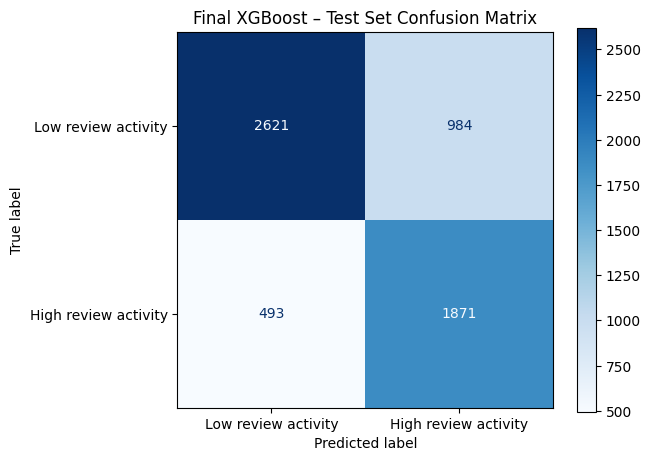

In [21]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

final_test_pred = (final_test_proba >= selected_threshold).astype("int8")
tn, fp, fn, tp = confusion_matrix(
    y_test, final_test_pred, labels=[0, 1]
).ravel()

print(f"True negatives: {tn} | False positives: {fp}")
print(f"False negatives: {fn} | True positives: {tp}")

ConfusionMatrixDisplay.from_predictions(
    y_true=y_test,
    y_pred=final_test_pred,
    labels=[0, 1],
    display_labels=["Low review activity", "High review activity"],
    values_format="d",
    cmap="Blues"
)
plt.title("Final XGBoost – Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

In the original completed run, the model correctly identified **1,871 of 2,364** positive test listings (recall ≈ 79.2%). It also produced **984 false positives** and **493 false negatives**. These errors illustrate the precision–recall trade-off at the selected threshold.

# 11. Model Interpretation

Understanding which features influence model predictions is essential for interpreting the results beyond predictive performance.

Two complementary methods were used:

- **Permutation Importance** to measure the contribution of individual predictors to model performance.
- **SHAP** to examine the magnitude of feature contributions.

These methods describe the model's predictive behavior, not causal relationships.

## 11.1 Permutation Feature Importance

Permutation importance was calculated for the tuned XGBoost model using the validation set. Each predictor was randomly shuffled 10 times, and the resulting decrease in ROC AUC was measured.

Larger decreases indicate greater reliance on a predictor, while values close to zero suggest a limited individual contribution.

In [22]:
from sklearn.inspection import permutation_importance

permutation_result = permutation_importance(
    estimator=xgb_selected_model,
    X=X_val_raw,
    y=y_val,
    scoring="roc_auc",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=1
)

xgb_permutation_importance = (
    pd.DataFrame({
        "feature": X_val_raw.columns,
        "importance_mean": permutation_result.importances_mean,
        "importance_std": permutation_result.importances_std
    })
    .sort_values("importance_mean", ascending=False)
    .reset_index(drop=True)
)

xgb_permutation_importance.insert(
    0, "rank", np.arange(1, len(xgb_permutation_importance) + 1)
)

display(xgb_permutation_importance.head(15).round(4))

,rank,feature,importance_mean,importance_std
0,1,host_acceptance_rate,0.0474,0.0032
1,2,availability_30,0.0369,0.0020
2,3,minimum_nights,0.0303,0.0032
3,4,distance_to_center_km,0.0223,0.0021
4,5,host_response_time,0.0194,0.0011
5,6,host_response_rate,0.0174,0.0025
6,7,price,0.0140,0.0013
7,8,amenities_count,0.0129,0.0009
8,9,availability_365,0.0115,0.0013
9,10,price_per_person,0.0110,0.0014


### 11.1.1 Permutation Importance Results

Host acceptance rate, 30-day availability, and minimum stay requirements were the most influential predictors, followed by distance to the city center and host response time.

These findings suggest that the model relies more heavily on availability, booking conditions, and host-related characteristics than on pricing alone.

Permutation importance measures the model's reliance on individual features, but does not establish the direction of their effects or imply causality.

## 11.2 SHAP Analysis

SHAP was used to examine the magnitude of feature contributions to XGBoost predictions.

The analysis was performed on a reproducible sample of 2,000 validation listings using the tuned XGBoost model trained on the training set.

SHAP values are calculated on the model's raw prediction scale (log-odds), rather than as direct changes in predicted probability. These contributions describe the model's behavior and should not be interpreted as causal effects.

In [23]:
import shap

xgb_preprocessor = xgb_selected_model.named_steps["preprocessor"]
xgb_classifier = xgb_selected_model.named_steps["classifier"]

X_val_shap_raw = X_val_raw.sample(
    n=min(2000, len(X_val_raw)),
    random_state=RANDOM_STATE
)

X_val_shap_transformed = xgb_preprocessor.transform(X_val_shap_raw)

if hasattr(X_val_shap_transformed, "toarray"):
    X_val_shap_transformed = X_val_shap_transformed.toarray()

shap_feature_names = xgb_preprocessor.get_feature_names_out()

X_val_shap_df = pd.DataFrame(
    X_val_shap_transformed,
    columns=shap_feature_names,
    index=X_val_shap_raw.index
)

shap_explainer = shap.TreeExplainer(xgb_classifier)
xgb_shap_values = shap_explainer(X_val_shap_df)

print("Listings analyzed:", len(X_val_shap_df))
print("Features after preprocessing:", X_val_shap_df.shape[1])
print("SHAP values shape:", xgb_shap_values.values.shape)

Listings analyzed: 2000
Features after preprocessing: 62
SHAP values shape: (2000, 62)


### 11.2.1 Aggregated SHAP Feature Importance

SHAP values were aggregated to recover the importance of the original **22 predictors**, combining contributions from one-hot encoded categories.

The ranking is based on mean absolute SHAP values and indicates the overall magnitude of each feature's contribution, regardless of direction. Categorical predictors with multiple encoded columns should be compared with some caution.

In [24]:
shap_importance = pd.DataFrame({
    "transformed_feature": shap_feature_names,
    "mean_abs_shap": np.abs(xgb_shap_values.values).mean(axis=0)
})

def original_feature_name(name):
    name = name.split("__", 1)[-1]

    for feature in CATEGORICAL_FEATURES:
        if name.startswith(f"{feature}_"):
            return feature

    return name

shap_importance["feature"] = (
    shap_importance["transformed_feature"]
    .apply(original_feature_name)
)

shap_importance_original = (
    shap_importance
    .groupby("feature", as_index=False)["mean_abs_shap"]
    .sum()
    .sort_values("mean_abs_shap", ascending=False)
    .reset_index(drop=True)
)

assert set(shap_importance_original["feature"]) == set(FEATURE_COLUMNS)

display(shap_importance_original.head(15).round(4))

,feature,mean_abs_shap
0,availability_30,0.5045
1,host_acceptance_rate,0.4592
2,minimum_nights,0.3650
3,host_response_time,0.3393
4,distance_to_center_km,0.3311
5,price,0.2807
6,amenities_count,0.2315
7,price_per_person,0.1965
8,availability_365,0.1910
9,calculated_host_listings_count_entire_homes,0.1894


### 11.2.2 SHAP Interpretation

SHAP analysis identified availability, host acceptance rate, minimum stay requirements, and host response time as key contributors to XGBoost predictions.

These results are broadly consistent with permutation importance, suggesting that booking conditions and host-related characteristics play a central role in the model's predictive behavior.

SHAP importance reflects the magnitude of feature contributions, not their direction or causal effects.

# 12. Conclusions

This project investigated whether future Airbnb review activity in London could be predicted using listing characteristics available in September 2025, without relying on historical review counts.

Four classification algorithms were compared: Logistic Regression, Random Forest, XGBoost, and CatBoost. Following host-grouped cross-validation and hyperparameter tuning, **XGBoost was selected as the final model**.

The final model achieved a **ROC AUC of 0.8382** and **recall of 0.7915** on the independent test set in the original completed run, demonstrating its ability to identify listings with high future review activity.

Feature importance analysis highlighted availability, booking conditions, and host-related characteristics as key contributors to predictions.

### Limitations

- Review activity is an indirect indicator of demand rather than a direct measure of bookings or revenue.
- The analysis covers one city and a specific observation period, limiting generalizability.
- Feature importance reflects predictive associations, not causal relationships.

Overall, the project demonstrates an end-to-end machine learning workflow, from data preparation and leakage-aware validation to model optimization, independent testing, and interpretation.